<a href="https://colab.research.google.com/github/Duman18/portfolio-risk-engine/blob/main/02_var.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

url = "https://raw.githubusercontent.com/Duman18/portfolio-risk-engine/refs/heads/main/returns.csv"
returns = pd.read_csv(url, index_col=0, parse_dates=True)

weights = np.array([0.2, 0.2, 0.2, 0.2, 0.2])
port_returns = returns.dot(weights)

V = 1_000_000    # portfolio value in HK$
port_returns.describe()

,0
count,2707.000000
mean,0.000554
std,0.014490
min,-0.132854
25%,-0.007536
50%,0.000473
75%,0.008132
max,0.093687


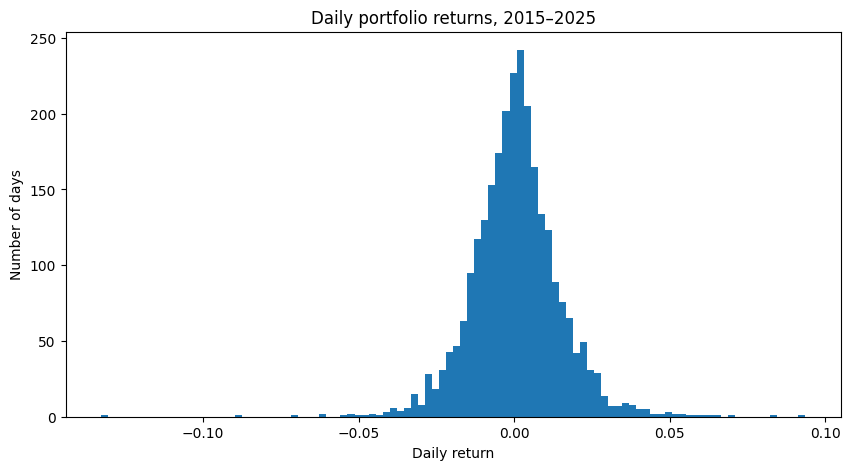

In [2]:
plt.figure(figsize=(10,5))
plt.hist(port_returns, bins=100)
plt.title("Daily portfolio returns, 2015–2025")
plt.xlabel("Daily return")
plt.ylabel("Number of days")
plt.show()

In [3]:
q = np.percentile(port_returns, 5)
hist_var = -q * V

print("5% worst-day return:", round(q*100, 2), "%")
print("Historical 95% VaR: HK$", round(hist_var))

5% worst-day return: -2.16 %
Historical 95% VaR: HK$ 21586


In [4]:
mu = port_returns.mean()
sigma = port_returns.std()

z = norm.ppf(0.05)
param_var = -(mu + z * sigma) * V

print("Average daily return:", round(mu*100, 3), "%")
print("Daily volatility:", round(sigma*100, 2), "%")
print("Parametric 95% VaR: HK$", round(param_var))

Average daily return: 0.055 %
Daily volatility: 1.45 %
Parametric 95% VaR: HK$ 23280


In [5]:
np.random.seed(42)
sim = np.random.normal(mu, sigma, 100_000)

mc_var = -np.percentile(sim, 5) * V
print("Monte Carlo 95% VaR: HK$", round(mc_var))

Monte Carlo 95% VaR: HK$ 23260


In [6]:
rows = []
for cl in [0.95, 0.99]:
    a = 1 - cl
    hist  = -np.percentile(port_returns, a*100) * V
    param = -(mu + norm.ppf(a) * sigma) * V
    mc    = -np.percentile(sim, a*100) * V
    rows.append([f"{int(cl*100)}%", hist, param, mc])

var_table = pd.DataFrame(rows, columns=["Confidence", "Historical", "Parametric", "Monte Carlo"])
var_table = var_table.set_index("Confidence").round(0)
var_table

,Historical,Parametric,Monte Carlo
Confidence,,,
95%,21586.0,23280.0,23260.0
99%,35116.0,33155.0,33275.0


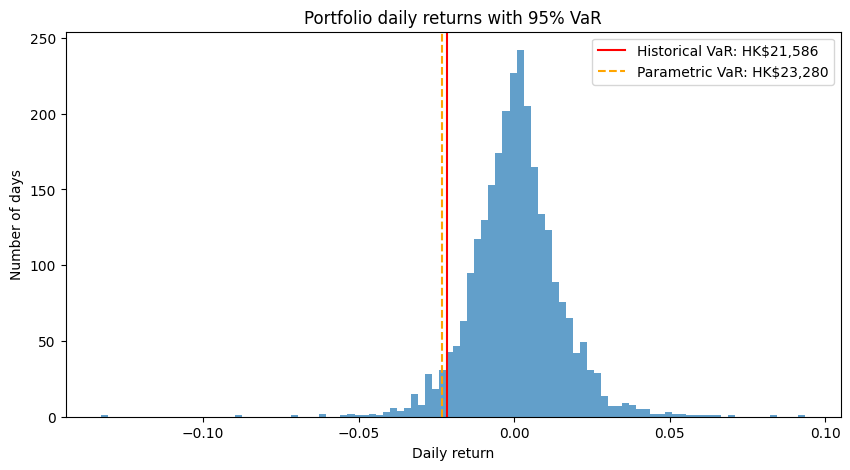

In [7]:
plt.figure(figsize=(10,5))
plt.hist(port_returns, bins=100, alpha=0.7)
plt.axvline(-hist_var/V,  color="red",    label=f"Historical VaR: HK${hist_var:,.0f}")
plt.axvline(-param_var/V, color="orange", linestyle="--", label=f"Parametric VaR: HK${param_var:,.0f}")
plt.title("Portfolio daily returns with 95% VaR")
plt.xlabel("Daily return")
plt.ylabel("Number of days")
plt.legend()
plt.savefig("var_chart.png", dpi=150, bbox_inches="tight")
plt.show()

Results
At 95% confidence, the 1-day VaR of the HK$1,000,000 portfolio is HK$21,586 (Historical) and HK$23,280 (Parametric). Monte Carlo gives almost the same value as Parametric, because it simulates from the same normal distribution.
At 99%, Historical VaR is HK$35,116 and Parametric VaR is HK$33,155. (If Historical is higher:) This shows that real returns have fat tails: extreme losses happen more often than the normal distribution predicts, so the Parametric method underestimates risk in the worst cases.
